# 02. Funnel Analysis — where do Northline shoppers drop off?

**Question:** where in the shopping journey do we lose the most shoppers, and which shoppers?

**Approach**
1. Build one row per session with the time each funnel step first happened.
2. Split the journey in two: the **browse funnel** (view → cart → checkout) and the **checkout funnel** (checkout → shipping → payment → purchase).
3. Compare segments to find the step that behaves *abnormally*, not just the step with the biggest drop.
4. Test the root cause with natural experiments in the calendar.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CLEAN = Path(r"E:\Northline\clean")

sessions = pd.read_parquet(CLEAN / "sessions.parquet")
users = pd.read_parquet(CLEAN / "users.parquet", columns=["user_id", "loyalty_member"])
orders = pd.read_parquet(CLEAN / "orders.parquet")
STEPS = ["view_item", "add_to_cart", "begin_checkout", "add_shipping_info", "add_payment_info", "purchase"]
events = pd.read_parquet(CLEAN / "events.parquet",
                         columns=["session_id", "user_id", "event_name", "event_ts", "cart_value"],
                         filters=[("event_name", "in", STEPS)])
print(f"{len(sessions):,} sessions · {len(events):,} funnel events · {len(orders):,} orders")

382,692 sessions · 845,837 funnel events · 13,301 orders


## Period labels

The quarter has very different shopping periods, so every cut can be split by them.

In [7]:
PERIODS = [  # (start, end, label)
    ("2025-10-01", "2025-11-20", "1 Baseline (Oct 1–Nov 20)"),
    ("2025-11-21", "2025-11-26", "2 Early Black Friday"),
    ("2025-11-27", "2025-12-01", "3 Thanksgiving–Cyber Monday"),
    ("2025-12-02", "2025-12-18", "4 December gifting"),
    ("2025-12-19", "2025-12-23", "5 After shipping cutoff"),
    ("2025-12-24", "2025-12-25", "6 Christmas"),
    ("2025-12-26", "2025-12-31", "7 After-Christmas sale"),
]

def period_of(dates):
    d = pd.to_datetime(dates)
    out = pd.Series(index=d.index, dtype="object")
    for start, end, label in PERIODS:
        out[(d >= start) & (d <= end)] = label
    return out

sessions["period"] = period_of(sessions.session_date)
sessions = sessions.merge(users, on="user_id", how="left")
sessions.period.value_counts().sort_index()

period
1 Baseline (Oct 1–Nov 20)      147763
2 Early Black Friday            28025
3 Thanksgiving–Cyber Monday     43586
4 December gifting             102606
5 After shipping cutoff         23969
6 Christmas                      4621
7 After-Christmas sale          32122
Name: count, dtype: int64

## One row per session: when did each step first happen?

A step only counts if it happened **after** the previous step (an ordered funnel). The checkout steps are ordered from `begin_checkout`, because some shoppers resume a cart saved in an earlier session and go straight to checkout.

In [8]:
first = (events.groupby(["session_id", "event_name"], observed=True).event_ts.min()
               .unstack().reindex(columns=STEPS))
cart_at_checkout = (events[events.event_name == "begin_checkout"]
                    .groupby("session_id").cart_value.first())

f = sessions.set_index("session_id")[["user_id", "session_date", "device", "browser", "channel",
                                      "is_returning", "loyalty_member", "period"]].join(first)
f["cart_value"] = cart_at_checkout

def after(a, b):
    """step b happened, at or after step a"""
    return f[b].notna() & f[a].notna() & (f[b] >= f[a])

f["s_view"] = f.view_item.notna()
f["s_cart"] = after("view_item", "add_to_cart")
f["s_checkout_from_cart"] = f.s_cart & after("add_to_cart", "begin_checkout")
f["s_checkout"] = f.begin_checkout.notna()                     # any checkout, incl. resumed carts
f["s_shipping"] = after("begin_checkout", "add_shipping_info")
f["s_payment"] = f.s_shipping & after("add_shipping_info", "add_payment_info")
f["s_purchase"] = f.s_payment & after("add_payment_info", "purchase")

resumed = (f.s_checkout & ~f.s_checkout_from_cart).sum() / f.s_checkout.sum()
print(f"Checkouts that came from a cart saved in an earlier session: {resumed:.1%}")

Checkouts that came from a cart saved in an earlier session: 16.0%


## The overall funnel

In [9]:
overall = pd.DataFrame({
    "sessions": [len(f), f.s_view.sum(), f.s_cart.sum(), f.s_checkout.sum(),
                 f.s_shipping.sum(), f.s_payment.sum(), f.s_purchase.sum()],
}, index=["All sessions", "Viewed a product", "Added to cart", "Began checkout",
          "Entered shipping", "Entered payment", "Purchased"])
overall["% of all sessions"] = overall.sessions / len(f) * 100
overall["% of previous step"] = overall.sessions / overall.sessions.shift() * 100
overall

,sessions,% of all sessions,% of previous step
All sessions,382692,100.00,NaN
Viewed a product,242406,63.34,63.34
Added to cart,30270,7.91,12.49
Began checkout,19444,5.08,64.24
Entered shipping,15911,4.16,81.83
Entered payment,14150,3.70,88.93
Purchased,13301,3.48,94.00


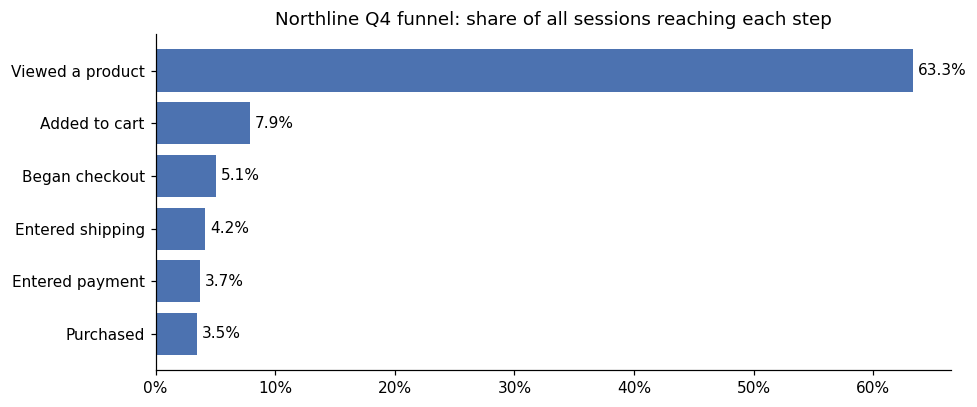

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = overall["% of all sessions"][1:]
bars = ax.barh(y.index[::-1], y.values[::-1], color="#4C72B0")
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in y.values[::-1]], padding=3)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Northline Q4 funnel: share of all sessions reaching each step")
plt.tight_layout(); plt.show()

The biggest absolute drop is **view → cart** (most sessions are browsing). That's normal for every retailer, so on its own it says nothing. To find a *problem*, compare segments: a step that's fine for one group and broken for another is fixable.

## Step conversion by device — which step is abnormal?

In [11]:
def step_table(df, by):
    g = df.groupby(by, observed=True)
    t = pd.DataFrame({
        "sessions": g.size(),
        "view → cart": g.s_cart.sum() / g.s_view.sum(),
        "cart → checkout": g.s_checkout_from_cart.sum() / g.s_cart.sum(),
        "checkout → shipping": g.s_shipping.sum() / g.s_checkout.sum(),
        "shipping → payment": g.s_payment.sum() / g.s_shipping.sum(),
        "payment → purchase": g.s_purchase.sum() / g.s_payment.sum(),
        "session conversion": g.s_purchase.sum() / g.size(),
    })
    return t

by_device = step_table(f, "device")
(by_device.style.format({"sessions": "{:,.0f}", **{c: "{:.1%}" for c in by_device.columns[1:]}})
          .background_gradient(axis=0, cmap="RdYlGn", subset=by_device.columns[1:6]))

,sessions,view → cart,cart → checkout,checkout → shipping,shipping → payment,payment → purchase,session conversion
device,,,,,,,
desktop,"119,060",14.7%,53.2%,88.9%,88.1%,93.9%,4.3%
mobile,"236,881",11.3%,54.4%,77.4%,89.6%,94.0%,3.1%
tablet,"26,751",13.3%,54.3%,82.0%,88.6%,94.5%,3.7%


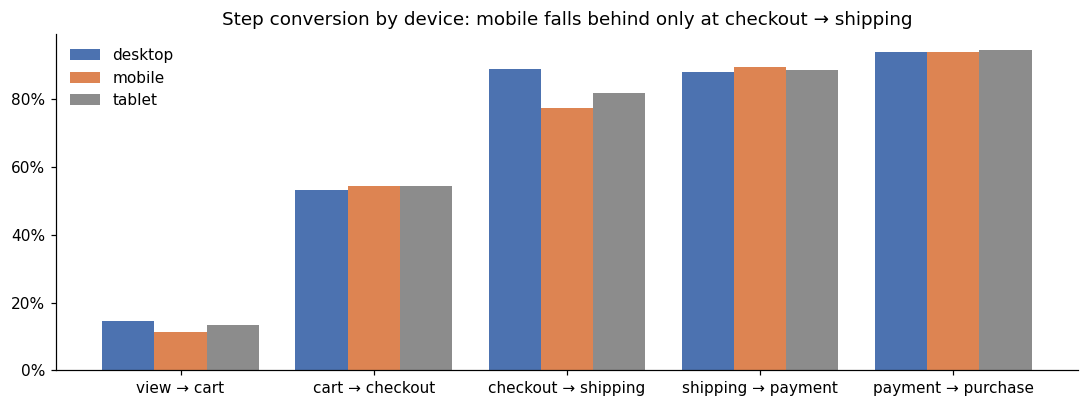

In [12]:
steps = by_device.columns[1:6]
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(steps)); w = 0.27
colors = {"desktop": "#4C72B0", "mobile": "#DD8452", "tablet": "#8C8C8C"}
for i, dev in enumerate(["desktop", "mobile", "tablet"]):
    b = ax.bar(x + (i - 1) * w, by_device.loc[dev, steps] * 100, w, label=dev, color=colors[dev])
ax.set_xticks(x, steps); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Step conversion by device: mobile falls behind only at checkout → shipping")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

In [13]:
gap = (by_device.loc["desktop", steps] - by_device.loc["mobile", steps]) * 100
gap.rename("desktop minus mobile (pts)").round(1)

view → cart            3.30
cart → checkout       -1.20
checkout → shipping   11.40
shipping → payment    -1.50
payment → purchase    -0.20
Name: desktop minus mobile (pts), dtype: float64

**Finding 1:** every checkout step is within ~1.5 points on mobile and desktop **except checkout → shipping**, where mobile trails by ~11 points. That's the abnormal leak.

What happens at the shipping step? It's where the **\$10.95 shipping fee** first appears for non-members with carts under \$49.

## Root cause: is it the shipping fee?

In [14]:
co = f[f.s_checkout].copy()
co["cart_size"] = np.where(co.cart_value < 49, "under $49", "$49+")
co["member"] = np.where(co.loyalty_member, "loyalty member (free shipping)", "non-member")

ship = (co.groupby(["member", "device", "cart_size"], observed=True)
          .agg(checkouts=("s_shipping", "size"), pass_rate=("s_shipping", "mean"))
          .unstack("cart_size"))
ship.columns = [f"{a} · {b}" for a, b in ship.columns]
ship = ship[["checkouts · under $49", "checkouts · $49+", "pass_rate · under $49", "pass_rate · $49+"]]
ship["penalty (pts)"] = (ship["pass_rate · $49+"] - ship["pass_rate · under $49"]) * 100
ship.style.format({c: "{:.1%}" for c in ship.columns if "pass" in c} |
                  {c: "{:,.0f}" for c in ship.columns if "checkouts" in c} | {"penalty (pts)": "{:.1f}"})

**Finding 2:** for **non-members**, carts under $49 pass the shipping step far less often, and the penalty is roughly **3x bigger on mobile** (\~17 pts) than desktop (\~6 pts). **Loyalty members**, who never pay shipping, show almost no small-cart penalty. That points straight at the fee.

### Natural experiments in the calendar
Two days changed the shipping rules for everyone, so they work like experiments:
- **Dec 14, Free Shipping Day:** no fee on any order.
- **Dec 19–23, after the standard-shipping cutoff:** only $19.95 express shipping for non-members, whatever the cart size.

In [15]:
nm = co[~co.loyalty_member].copy()
nm["window"] = np.select(
    [nm.session_date.between("2025-12-08", "2025-12-13"),
     nm.session_date == "2025-12-14",
     nm.session_date.between("2025-12-19", "2025-12-23")],
    ["Dec 8–13 (normal: fee under $49)", "Dec 14 (Free Shipping Day)", "Dec 19–23 (express only, $19.95)"],
    default=None)
nat = (nm.dropna(subset=["window"])
         .groupby(["window", "device", "cart_size"], observed=True).s_shipping.mean()
         .unstack(["device", "cart_size"])[[("mobile", "under $49"), ("mobile", "$49+"),
                                            ("desktop", "under $49"), ("desktop", "$49+")]])
nat.loc[["Dec 8–13 (normal: fee under $49)", "Dec 14 (Free Shipping Day)",
         "Dec 19–23 (express only, $19.95)"]].style.format("{:.1%}")

**Finding 3:** remove the fee (Dec 14) and mobile small carts pass the shipping step about as often as big ones (~81% vs. ~70% the week before). Charge everyone a bigger fee (Dec 19–23) and *every* cart size drops, big carts included (mobile $49+ falls from ~82% to ~69%). The fee is the cause, and mobile shoppers are most sensitive to it.

## Other segments

In [17]:
by_channel = step_table(f, "channel").sort_values("session conversion", ascending=False)
by_channel.style.format({"sessions": "{:,.0f}", **{c: "{:.1%}" for c in by_channel.columns[1:]}})

,sessions,view → cart,cart → checkout,checkout → shipping,shipping → payment,payment → purchase,session conversion
channel,,,,,,,
email,"36,288",19.0%,58.3%,82.7%,88.7%,94.4%,5.2%
affiliate,"24,402",14.0%,55.0%,82.2%,90.3%,93.9%,4.1%
paid_search,"83,501",12.9%,54.4%,81.7%,88.6%,94.1%,4.0%
organic_search,"125,217",11.8%,53.2%,81.6%,89.1%,93.9%,3.3%
direct,"58,126",14.9%,56.0%,82.8%,88.7%,93.9%,3.1%
(not set),"7,458",11.3%,52.2%,81.1%,91.2%,92.4%,3.1%
social,"47,700",7.0%,45.0%,78.9%,88.5%,93.9%,1.7%


In [18]:
f["visitor"] = np.where(f.is_returning, "returning", "new")
f["membership"] = np.where(f.loyalty_member, "loyalty member", "non-member")
seg = pd.concat({"visitor": step_table(f, "visitor"), "membership": step_table(f, "membership")})
seg.style.format({"sessions": "{:,.0f}", **{c: "{:.1%}" for c in seg.columns[1:]}})

In [19]:
by_period = step_table(f, "period")
by_period.style.format({"sessions": "{:,.0f}", **{c: "{:.1%}" for c in by_period.columns[1:]}})

,sessions,view → cart,cart → checkout,checkout → shipping,shipping → payment,payment → purchase,session conversion
period,,,,,,,
1 Baseline (Oct 1–Nov 20),"147,763",10.8%,52.5%,81.2%,89.1%,94.1%,2.8%
2 Early Black Friday,"28,025",12.8%,52.7%,81.8%,88.8%,93.1%,3.4%
3 Thanksgiving–Cyber Monday,"43,586",16.1%,56.1%,83.5%,89.1%,94.6%,4.8%
4 December gifting,"102,606",13.5%,54.5%,83.0%,88.6%,93.6%,3.9%
5 After shipping cutoff,"23,969",11.7%,55.1%,77.1%,90.0%,94.2%,3.3%
6 Christmas,"4,621",8.9%,49.6%,75.3%,88.2%,97.1%,2.2%
7 After-Christmas sale,"32,122",12.8%,55.3%,81.2%,88.7%,94.1%,3.7%


**Finding 4:** email (\~5%) and paid search convert best; social is lowest (~1.7%). Returning visitors and loyalty members convert better. Thanksgiving–Cyber Monday converts best of all; the post-cutoff window shows the shipping-step drop seen above.

## Daily trend

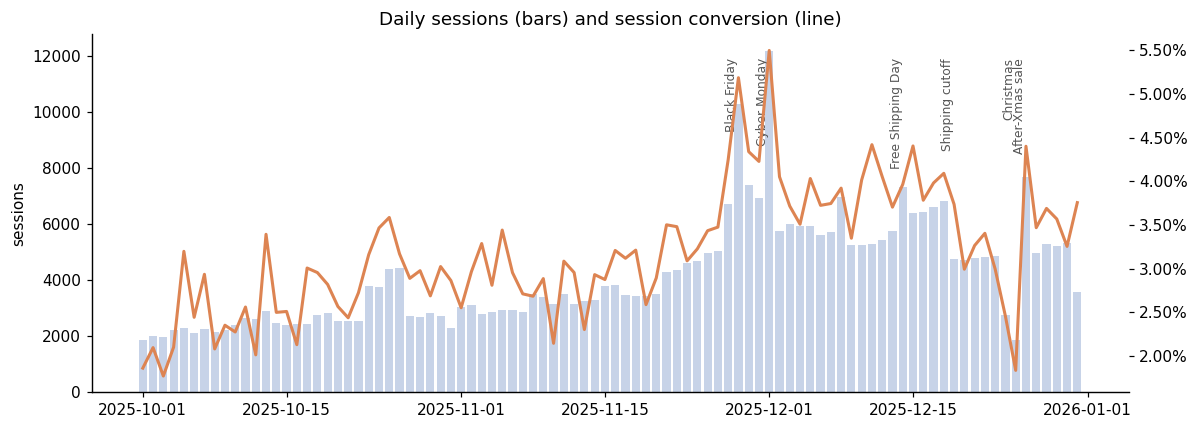

In [20]:
daily = (f.groupby("session_date")
          .agg(sessions=("s_view", "size"), purchases=("s_purchase", "sum")))
daily["conversion"] = daily.purchases / daily.sessions
rev = orders.assign(d=orders.order_ts.dt.normalize()).groupby("d").order_revenue.sum()
daily["gross_revenue"] = rev.reindex(daily.index).fillna(0)

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(daily.index, daily.sessions, color="#C7D3E8", label="sessions")
ax2 = ax1.twinx()
ax2.plot(daily.index, daily.conversion * 100, color="#DD8452", lw=2, label="conversion %")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter()); ax2.spines["top"].set_visible(False)
for d, lab in [("2025-11-28", "Black Friday"), ("2025-12-01", "Cyber Monday"),
               ("2025-12-14", "Free Shipping Day"), ("2025-12-19", "Shipping cutoff"),
               ("2025-12-25", "Christmas"), ("2025-12-26", "After-Xmas sale")]:
    ax1.annotate(lab, (pd.Timestamp(d), daily.sessions.max() * 0.98), rotation=90,
                 fontsize=8, ha="right", va="top", color="#555")
ax1.set_title("Daily sessions (bars) and session conversion (line)")
ax1.set_ylabel("sessions"); plt.tight_layout(); plt.show()

In [22]:
daily.sort_values("sessions", ascending=False).head(6)

,sessions,purchases,conversion,gross_revenue
session_date,,,,
2025-12-01,12184,670,0.05,"70,411.05"
2025-11-28,10295,534,0.05,"55,832.23"
2025-12-26,7701,339,0.04,"31,394.41"
2025-11-29,7419,322,0.04,"33,854.94"
2025-12-14,7339,291,0.04,"35,749.53"
2025-12-08,6960,273,0.04,"37,870.74"


## User-level funnel

In [24]:
u = f.groupby("user_id").agg(viewed=("s_view", "any"), carted=("s_cart", "any"),
                             checkout=("s_checkout", "any"), purchased=("s_purchase", "any"))
user_funnel = pd.DataFrame({"users": u.sum()})
user_funnel["% of users"] = user_funnel.users / len(u) * 100
print(f"Users: {len(u):,}")
print(f"Session conversion: {f.s_purchase.mean():.2%}   User conversion over Q4: {u.purchased.mean():.2%}")
user_funnel

Users: 240,000
Session conversion: 3.48%   User conversion over Q4: 5.22%


,users,% of users
viewed,176110,73.38
carted,27897,11.62
checkout,17409,7.25
purchased,12525,5.22


In [25]:
# How many buyers bought in a later session than the one where they first added to cart?
first_cart = f[f.s_cart].reset_index().sort_values("add_to_cart").groupby("user_id").session_id.first()
first_buy = f[f.s_purchase].reset_index().sort_values("purchase").groupby("user_id").session_id.first()
both = pd.concat([first_cart, first_buy], axis=1, keys=["cart_session", "buy_session"]).dropna()
print(f"Buyers who purchased in a LATER session than their first add-to-cart: "
      f"{(both.cart_session != both.buy_session).mean():.1%}")

Buyers who purchased in a LATER session than their first add-to-cart: 18.6%


**Finding 5:** about 1 in 5 buyers come back in a later session to finish. A session-only funnel therefore understates how well carts eventually convert; report both views.

## Bonus: categories, returns and repeat purchase

In [26]:
items = pd.read_parquet(CLEAN / "order_items.parquet")
items = items.merge(orders[["order_id", "order_ts"]], on="order_id")
items["month"] = items.order_ts.dt.strftime("%Y-%m").replace({"2026-01": "2025-12"})
mix = pd.crosstab(items.item_category, items.month, values=items.line_net_amount, aggfunc="sum", normalize="columns")
mix.style.format("{:.1%}").background_gradient(axis=1, cmap="Blues")

month,2025-10,2025-11,2025-12
item_category,,,
Beauty,5.4%,6.5%,9.1%
Handbags,14.8%,14.0%,15.6%
Home,11.2%,13.1%,13.8%
Jewelry,10.0%,11.3%,14.2%
Kids,3.2%,3.4%,4.8%
Men's Apparel,10.8%,11.6%,10.0%
Shoes,21.8%,20.4%,16.5%
Women's Apparel,22.8%,19.8%,16.0%


In [27]:
items.groupby("item_category", observed=True).is_returned.mean().sort_values(ascending=False).rename("return rate").map("{:.1%}".format)

item_category
Women's Apparel    26.1%
Shoes              21.9%
Men's Apparel      21.8%
Handbags           15.0%
Kids               14.1%
Jewelry            13.0%
Home               10.4%
Beauty              6.9%
Name: return rate, dtype: object

In [28]:
fo = orders.sort_values("order_ts").groupby("user_id").order_ts.first().rename("first_order")
o2 = orders.merge(fo, on="user_id")
repeat30 = o2[(o2.order_ts > o2.first_order) & (o2.order_ts <= o2.first_order + pd.Timedelta(days=30))].user_id.unique()
coh = fo.to_frame()
coh["cohort"] = pd.cut(coh.first_order, pd.to_datetime(["2025-10-01", "2025-11-01", "2025-11-27", "2025-12-02", "2026-01-02"]),
                       labels=["Oct", "Nov (pre-Black Friday)", "Thanksgiving–Cyber Monday", "Dec"], right=False)
coh["repeat_30d"] = coh.index.isin(repeat30)
coh["days_observed"] = (pd.Timestamp("2025-12-31") - coh.first_order).dt.days.clip(upper=30)
(coh.groupby("cohort", observed=True)
    .agg(first_time_buyers=("repeat_30d", "size"), repeat_within_30d=("repeat_30d", "mean"),
         avg_days_observed=("days_observed", "mean")))

,first_time_buyers,repeat_within_30d,avg_days_observed
cohort,,,
Oct,2216,0.05,30.00
Nov (pre-Black Friday),2693,0.06,30.00
Thanksgiving–Cyber Monday,1999,0.04,29.68
Dec,5617,0.04,14.72


Deal-driven Thanksgiving–Cyber Monday first-time buyers come back least within 30 days. December's cohort can't be judged fairly: most of those buyers have fewer than 30 days of data (right-censoring).